# <center>Taller de Aprendizaje Automático</center>
## <center>Comparación i1 vs i2 para el mejor modelo de árboles</center>
### <center>XGBoost tuneado sobre `processed/i1` y `processed/i2_arboles`</center>

Este notebook compara dos variantes de preprocesamiento usando exactamente el mismo modelo de árboles que quedó como mejor candidato en `7. Arboles/arboles de desiciones.ipynb`.

La idea es mantener fija la arquitectura del modelo y cambiar solo el dataset de entrada:

- `i1`: datos procesados con descarte de columnas, imputación, one-hot y escalado.
- `i2_arboles`: datos procesados sin descarte, sin imputación, sin escalado y con `-999` reemplazado por `NaN`.

Para que la comparación sea justa, este cuaderno vuelve a entrenar el mismo `XGBClassifier` sobre ambos datasets usando un único split estratificado compartido.

## Configuración y carga de artefactos

Se cargan los datasets procesados desde `data/higgs-boson/processed/i1` y `data/higgs-boson/processed/i2_arboles`. También se valida que ambos representen exactamente las mismas filas etiquetadas, para poder usar el mismo holdout en la comparación.

In [1]:
from __future__ import annotations

from datetime import datetime
from pathlib import Path
import os
import subprocess
import time

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

BEST_XGB_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": SEED,
    "learning_rate": 0.05,
    "n_estimators": 400,
    "max_depth": 6,
    "scale_pos_weight": 1.5346,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "tree_method": "hist",
    "n_jobs": -1,
    "missing": np.nan,
}

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBClassifier = None
    XGBOOST_AVAILABLE = False
    print("xgboost no está instalado. Para ejecutar este notebook hay que instalarlo primero.")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


def load_processed_dataset(processed_name: str) -> dict[str, pd.DataFrame | pd.Series | Path]:
    root = find_project_root()
    processed_dir = root / "data" / "higgs-boson" / "processed" / processed_name

    if not processed_dir.exists():
        raise FileNotFoundError(f"No se encontró el directorio procesado: {processed_dir}")

    X = pd.read_csv(processed_dir / "X_train_processed.csv")
    X_test = pd.read_csv(processed_dir / "X_test_processed.csv")
    y_raw = pd.read_csv(processed_dir / "y_train.csv")
    train_weight_raw = pd.read_csv(processed_dir / "train_weight.csv")
    event_id = pd.read_csv(processed_dir / "train_event_id.csv")
    test_event_id = pd.read_csv(processed_dir / "test_event_id.csv")

    if "Label" not in y_raw.columns:
        raise ValueError(f"y_train.csv de {processed_name} no tiene la columna Label")
    if "Weight" not in train_weight_raw.columns:
        raise ValueError(f"train_weight.csv de {processed_name} no tiene la columna Weight")
    if "EventId" not in event_id.columns:
        raise ValueError(f"train_event_id.csv de {processed_name} no tiene la columna EventId")
    if "EventId" not in test_event_id.columns:
        raise ValueError(f"test_event_id.csv de {processed_name} no tiene la columna EventId")
    if len(X_test) != len(test_event_id):
        raise ValueError(f"X_test_processed y test_event_id no tienen la misma cantidad de filas en {processed_name}")

    label_map = {"b": 0, "s": 1}
    unknown_labels = sorted(set(y_raw["Label"].unique()) - set(label_map))
    if unknown_labels:
        raise ValueError(f"Etiquetas inesperadas en {processed_name}: {unknown_labels}")

    y = y_raw["Label"].map(label_map).astype(np.int8)
    train_weight = train_weight_raw["Weight"].astype(np.float64)

    return {
        "processed_name": processed_name,
        "processed_dir": processed_dir,
        "X": X,
        "X_test": X_test,
        "y": y,
        "train_weight": train_weight,
        "event_id": event_id["EventId"].copy(),
        "test_event_id": test_event_id["EventId"].copy(),
    }


project_root = find_project_root()
i1_data = load_processed_dataset("i1")
i2_data = load_processed_dataset("i2_arboles")

print(f"project_root: {project_root}")
print(f"i1 dir: {i1_data['processed_dir']}")
print(f"i2 dir: {i2_data['processed_dir']}")

project_root: /home/santig14/fing/taa/1_TallerAA
i1 dir: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i1
i2 dir: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i2_arboles


In [2]:
if not i1_data["event_id"].equals(i2_data["event_id"]):
    raise ValueError("Los EventId de i1 e i2_arboles no coinciden fila a fila.")

if not i1_data["y"].equals(i2_data["y"]):
    raise ValueError("Las etiquetas de i1 e i2_arboles no coinciden fila a fila.")

if not i1_data["train_weight"].equals(i2_data["train_weight"]):
    raise ValueError("Los pesos de train de i1 e i2_arboles no coinciden fila a fila.")

if not i1_data["test_event_id"].equals(i2_data["test_event_id"]):
    raise ValueError("Los EventId de test de i1 e i2_arboles no coinciden fila a fila.")

y = i1_data["y"].copy()
train_weight = i2_data["train_weight"].copy()
test_event_id = i2_data["test_event_id"].copy()

summary_df = pd.DataFrame(
    [
        {
            "dataset": "i1",
            "rows": len(i1_data["X"]),
            "test_rows": len(i1_data["X_test"]),
            "feature_count": i1_data["X"].shape[1],
            "nan_count": int(i1_data["X"].isna().sum().sum()),
            "minus_999_count": int((i1_data["X"] == -999).sum().sum()),
        },
        {
            "dataset": "i2_arboles",
            "rows": len(i2_data["X"]),
            "test_rows": len(i2_data["X_test"]),
            "feature_count": i2_data["X"].shape[1],
            "nan_count": int(i2_data["X"].isna().sum().sum()),
            "minus_999_count": int((i2_data["X"] == -999).sum().sum()),
        },
    ]
)

print("Resumen de los datasets comparados:")
display(summary_df)
print("Distribución de clases compartida:")
print(y.value_counts().sort_index().rename(index={0: 'b', 1: 's'}).to_dict())
print(f"Suma total de pesos de train: {train_weight.sum():.6f}")

Resumen de los datasets comparados:


,dataset,rows,test_rows,feature_count,nan_count,minus_999_count
0,i1,250000,550000,26,0,0
1,i2_arboles,250000,550000,33,1580052,0


Distribución de clases compartida:
{'b': 164333, 's': 85667}
Suma total de pesos de train: 411691.835930


## Split compartido para una comparación justa

Se define un único holdout estratificado y se reutilizan exactamente los mismos índices para `i1` e `i2_arboles`. Así el cambio de performance se puede atribuir al preprocesamiento y no a una partición distinta.

In [3]:
row_indices = np.arange(len(y))
train_idx, valid_idx = train_test_split(
    row_indices,
    test_size=0.1,
    random_state=SEED,
    stratify=y,
)

X_i1_train = i1_data["X"].iloc[train_idx].astype(np.float32)
X_i1_valid = i1_data["X"].iloc[valid_idx].astype(np.float32)
X_i2_train = i2_data["X"].iloc[train_idx].astype(np.float32)
X_i2_valid = i2_data["X"].iloc[valid_idx].astype(np.float32)
X_i2_test = i2_data["X_test"].astype(np.float32)

y_train = y.iloc[train_idx].copy()
y_valid = y.iloc[valid_idx].copy()
weight_train = train_weight.iloc[train_idx].copy()
weight_valid = train_weight.iloc[valid_idx].copy()

neg_count = int((y_train == 0).sum())
pos_count = int((y_train == 1).sum())
scale_pos_weight_suggested = float(neg_count / pos_count)

split_summary_df = pd.DataFrame(
    [
        {
            "split": "train",
            "rows": len(train_idx),
            "class_b": int((y_train == 0).sum()),
            "class_s": int((y_train == 1).sum()),
            "weight_sum": float(weight_train.sum()),
        },
        {
            "split": "valid",
            "rows": len(valid_idx),
            "class_b": int((y_valid == 0).sum()),
            "class_s": int((y_valid == 1).sum()),
            "weight_sum": float(weight_valid.sum()),
        },
    ]
)

print("Resumen del split compartido:")
display(split_summary_df.round(6))
print(f"X_i1_train shape: {X_i1_train.shape}")
print(f"X_i2_train shape: {X_i2_train.shape}")
print(f"X_i2_test shape: {X_i2_test.shape}")
print(f"scale_pos_weight sugerido por este split: {scale_pos_weight_suggested:.4f}")
print(f"scale_pos_weight fijo del mejor XGBoost original: {BEST_XGB_PARAMS['scale_pos_weight']:.4f}")

Resumen del split compartido:


,split,rows,class_b,class_s,weight_sum
0,train,225000,147900,77100,370822.739836
1,valid,25000,16433,8567,40869.096094


X_i1_train shape: (225000, 26)
X_i2_train shape: (225000, 33)
X_i2_test shape: (550000, 33)
scale_pos_weight sugerido por este split: 1.9183
scale_pos_weight fijo del mejor XGBoost original: 1.5346


## Helpers de entrenamiento y evaluación

Se reutiliza la misma configuración del mejor XGBoost tuneado del notebook original. No se vuelven a buscar hiperparámetros: el objetivo acá es aislar el efecto del preprocesamiento.

In [4]:
def build_best_xgboost_model() -> XGBClassifier:
    if not XGBOOST_AVAILABLE:
        raise ImportError("xgboost no está disponible en el entorno actual.")
    return XGBClassifier(**BEST_XGB_PARAMS)


def predict_scores(model: XGBClassifier, X_frame: pd.DataFrame) -> np.ndarray:
    return model.predict_proba(X_frame)[:, 1]


def evaluate_classifier(
    model: XGBClassifier,
    X_frame: pd.DataFrame,
    y_true: pd.Series,
    dataset_name: str,
    fit_seconds: float,
) -> dict[str, float | int | str]:
    y_pred = model.predict(X_frame)
    y_score = predict_scores(model, X_frame)
    return {
        "dataset": dataset_name,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, y_score)),
        "fit_seconds": float(fit_seconds),
    }


def fit_and_evaluate_best_xgboost(
    X_train_frame: pd.DataFrame,
    X_valid_frame: pd.DataFrame,
    y_train_series: pd.Series,
    y_valid_series: pd.Series,
    dataset_name: str,
) -> tuple[XGBClassifier, dict[str, float | int | str]]:
    model = build_best_xgboost_model()
    start_time = time.perf_counter()
    model.fit(X_train_frame, y_train_series)
    fit_seconds = time.perf_counter() - start_time
    metrics = evaluate_classifier(model, X_valid_frame, y_valid_series, dataset_name, fit_seconds)
    metrics.update(
        {
            "feature_count": int(X_train_frame.shape[1]),
            "train_nan_count": int(X_train_frame.isna().sum().sum()),
            "valid_nan_count": int(X_valid_frame.isna().sum().sum()),
            "source": (
                f"lr={BEST_XGB_PARAMS['learning_rate']}, "
                f"estimators={BEST_XGB_PARAMS['n_estimators']}, "
                f"depth={BEST_XGB_PARAMS['max_depth']}, "
                f"spw={BEST_XGB_PARAMS['scale_pos_weight']:.4f}"
            ),
        }
    )
    return model, metrics


def ams_score(
    signal_weight: np.ndarray | float,
    background_weight: np.ndarray | float,
    br: float = 10.0,
) -> np.ndarray:
    signal_arr = np.asarray(signal_weight, dtype=np.float64)
    background_arr = np.asarray(background_weight, dtype=np.float64)
    radicand = 2.0 * (
        (signal_arr + background_arr + br) * np.log1p(signal_arr / (background_arr + br)) - signal_arr
    )
    return np.sqrt(np.clip(radicand, a_min=0.0, a_max=None))


def find_best_ams_threshold(
    y_true: pd.Series,
    y_scores: np.ndarray,
    weights: pd.Series | np.ndarray,
    br: float = 10.0,
) -> dict[str, float | int]:
    y_array = np.asarray(y_true, dtype=np.int8)
    score_array = np.asarray(y_scores, dtype=np.float64)
    weight_array = np.asarray(weights, dtype=np.float64)

    if not (len(y_array) == len(score_array) == len(weight_array)):
        raise ValueError("y_true, y_scores y weights deben tener la misma longitud.")

    order = np.argsort(score_array)[::-1]
    y_sorted = y_array[order]
    score_sorted = score_array[order]
    weight_sorted = weight_array[order]

    signal_cumsum = np.cumsum(np.where(y_sorted == 1, weight_sorted, 0.0))
    background_cumsum = np.cumsum(np.where(y_sorted == 0, weight_sorted, 0.0))

    candidate_mask = np.r_[score_sorted[1:] != score_sorted[:-1], True]
    candidate_indices = np.flatnonzero(candidate_mask)
    ams_values = ams_score(signal_cumsum[candidate_indices], background_cumsum[candidate_indices], br=br)

    best_position = int(np.argmax(ams_values))
    best_idx = int(candidate_indices[best_position])
    best_threshold = float(score_sorted[best_idx])
    best_pred = (score_array >= best_threshold).astype(np.int8)

    return {
        "threshold": best_threshold,
        "ams": float(ams_values[best_position]),
        "signal_weight": float(signal_cumsum[best_idx]),
        "background_weight": float(background_cumsum[best_idx]),
        "predicted_signal_count": int(best_pred.sum()),
        "predicted_background_count": int(len(best_pred) - best_pred.sum()),
        "precision": float(precision_score(y_array, best_pred, zero_division=0)),
        "recall": float(recall_score(y_array, best_pred, zero_division=0)),
        "f1": float(f1_score(y_array, best_pred, zero_division=0)),
        "candidate_threshold_count": int(len(candidate_indices)),
    }


def build_higgs_submission(
    event_ids: pd.Series,
    scores: np.ndarray,
    threshold: float,
) -> pd.DataFrame:
    score_array = np.asarray(scores, dtype=np.float64)
    if len(event_ids) != len(score_array):
        raise ValueError("event_ids y scores deben tener la misma longitud.")

    submission_df = pd.DataFrame(
        {
            "EventId": event_ids.astype(np.int64),
            "RankOrder": pd.Series(score_array).rank(method="first", ascending=True).astype(np.int64),
            "Class": np.where(score_array >= threshold, "s", "b"),
        }
    )
    return submission_df[["EventId", "RankOrder", "Class"]]


def validate_higgs_submission(submission_df: pd.DataFrame) -> dict[str, int]:
    expected_columns = ["EventId", "RankOrder", "Class"]
    if list(submission_df.columns) != expected_columns:
        raise ValueError(f"Las columnas del submission deben ser exactamente {expected_columns}.")

    if not submission_df["EventId"].is_unique:
        raise ValueError("EventId debe ser único en el submission.")

    rank_array = submission_df["RankOrder"].to_numpy(dtype=np.int64, copy=False)
    expected_rank = np.arange(1, len(submission_df) + 1, dtype=np.int64)
    if rank_array.min() != 1 or rank_array.max() != len(submission_df):
        raise ValueError("RankOrder debe ir de 1 a N.")
    if len(np.unique(rank_array)) != len(submission_df):
        raise ValueError("RankOrder debe ser único.")
    if not np.array_equal(np.sort(rank_array), expected_rank):
        raise ValueError("RankOrder debe contener todos los enteros de 1 a N.")

    invalid_classes = sorted(set(submission_df["Class"].unique()) - {"s", "b"})
    if invalid_classes:
        raise ValueError(f"Class solo puede contener 's' o 'b'. Se encontró: {invalid_classes}")

    return {
        "rows": int(len(submission_df)),
        "rank_min": int(rank_array.min()),
        "rank_max": int(rank_array.max()),
        "signal_count": int((submission_df["Class"] == "s").sum()),
        "background_count": int((submission_df["Class"] == "b").sum()),
    }


def save_higgs_submission(submission_df: pd.DataFrame, prefix: str) -> Path:
    results_dir = project_root / "results"
    results_dir.mkdir(parents=True, exist_ok=True)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    submission_path = results_dir / f"{prefix}_{timestamp}.csv"
    submission_df.to_csv(submission_path, index=False)
    return submission_path


def build_kaggle_submit_command(submission_path: Path, message: str) -> str:
    kaggle_config_dir = project_root / "keys"
    return (
        f"KAGGLE_CONFIG_DIR={kaggle_config_dir} "
        f"kaggle competitions submit -c higgs-boson "
        f"-f {submission_path} -m '{message}'"
    )


def plot_top_feature_importances(
    model: XGBClassifier,
    feature_names: list[str] | pd.Index,
    title: str,
    top_n: int = 15,
) -> None:
    importance_df = pd.DataFrame(
        {
            "feature": list(feature_names),
            "importance": model.feature_importances_,
        }
    ).sort_values("importance", ascending=False).head(top_n)

    plt.figure(figsize=(9, 5))
    plt.barh(importance_df["feature"][::-1], importance_df["importance"][::-1], color="#4C72B0")
    plt.xlabel("Importance")
    plt.title(title)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Reentrenamiento del mejor árbol sobre `i1`

Esta sección reconstruye el baseline de árboles sobre el dataset `i1`, pero dentro de un cuaderno nuevo y con el mismo split que luego se usará para `i2_arboles`. Eso deja una referencia comparable línea a línea.

In [5]:
best_xgboost_i1, best_xgboost_i1_metrics = fit_and_evaluate_best_xgboost(
    X_i1_train,
    X_i1_valid,
    y_train,
    y_valid,
    dataset_name="i1",
)

best_xgboost_i1_df = pd.DataFrame([best_xgboost_i1_metrics])
print("Resumen del mejor XGBoost reentrenado sobre i1:")
display(best_xgboost_i1_df.round(4))

Resumen del mejor XGBoost reentrenado sobre i1:


,dataset,accuracy,precision,recall,f1,auc,fit_seconds,feature_count,train_nan_count,valid_nan_count,source
0,i1,0.8311,0.7347,0.7937,0.7631,0.9057,5.9644,26,0,0,"lr=0.05, estimators=400, depth=6, spw=1.5346"


## Reentrenamiento del mejor árbol sobre `i2_arboles`

Acá se toma exactamente el mismo `XGBClassifier`, sin tocar hiperparámetros, y se lo entrena sobre la variante `i2_arboles` para medir cuánto cambia el rendimiento cuando el modelo recibe las features sin escalado y con faltantes como `NaN`.

In [6]:
best_xgboost_i2, best_xgboost_i2_metrics = fit_and_evaluate_best_xgboost(
    X_i2_train,
    X_i2_valid,
    y_train,
    y_valid,
    dataset_name="i2_arboles",
)

best_xgboost_i2_df = pd.DataFrame([best_xgboost_i2_metrics])
print("Resumen del mejor XGBoost reentrenado sobre i2_arboles:")
display(best_xgboost_i2_df.round(4))

Resumen del mejor XGBoost reentrenado sobre i2_arboles:


,dataset,accuracy,precision,recall,f1,auc,fit_seconds,feature_count,train_nan_count,valid_nan_count,source
0,i2_arboles,0.8356,0.742,0.7975,0.7688,0.909,7.8739,33,1422313,157739,"lr=0.05, estimators=400, depth=6, spw=1.5346"


## Comparación directa i1 vs i2

La comparación principal se hace sobre el mismo conjunto de validación. Se resumen métricas de clasificación, `ROC AUC`, tiempo de entrenamiento, cantidad de features y cantidad de `NaN` que recibió cada modelo.

Comparación final entre el mejor XGBoost sobre i1 e i2_arboles:


,dataset,source,feature_count,train_nan_count,valid_nan_count,accuracy,precision,recall,f1,auc,fit_seconds,delta_auc_vs_i1,delta_f1_vs_i1,delta_fit_seconds_vs_i1
0,i2_arboles,"lr=0.05, estimators=400, depth=6, spw=1.5346",33,1422313,157739,0.8356,0.7420,0.7975,0.7688,0.9090,7.8739,0.0033,0.0057,1.9095
1,i1,"lr=0.05, estimators=400, depth=6, spw=1.5346",26,0,0,0.8311,0.7347,0.7937,0.7631,0.9057,5.9644,0.0000,0.0000,0.0000


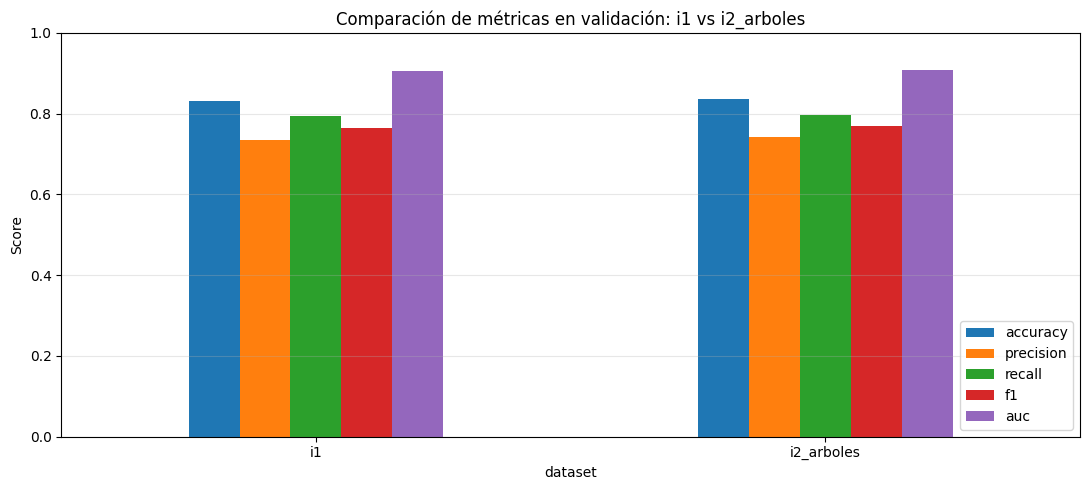

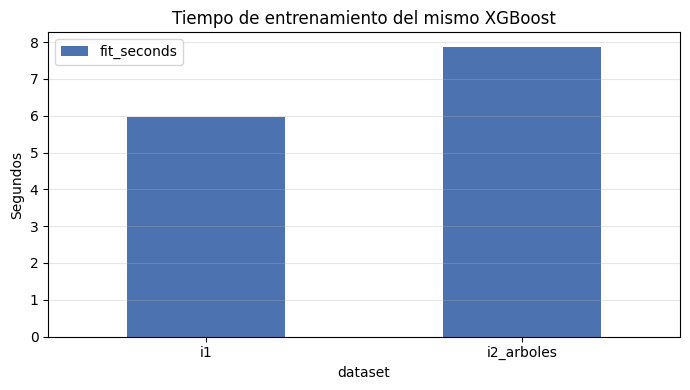

In [7]:
comparison_df = pd.DataFrame([best_xgboost_i1_metrics, best_xgboost_i2_metrics])
reference_i1 = comparison_df.loc[comparison_df["dataset"] == "i1"].iloc[0]

for metric in ["accuracy", "precision", "recall", "f1", "auc", "fit_seconds"]:
    comparison_df[f"delta_{metric}_vs_i1"] = comparison_df[metric] - float(reference_i1[metric])

comparison_display_columns = [
    "dataset",
    "source",
    "feature_count",
    "train_nan_count",
    "valid_nan_count",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc",
    "fit_seconds",
    "delta_auc_vs_i1",
    "delta_f1_vs_i1",
    "delta_fit_seconds_vs_i1",
]

comparison_ranked_df = comparison_df.sort_values(["auc", "f1"], ascending=False).reset_index(drop=True)

print("Comparación final entre el mejor XGBoost sobre i1 e i2_arboles:")
display(comparison_ranked_df[comparison_display_columns].round(4))

metric_plot_df = comparison_df.set_index("dataset")[["accuracy", "precision", "recall", "f1", "auc"]]
metric_plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0.0, 1.0), rot=0)
plt.ylabel("Score")
plt.title("Comparación de métricas en validación: i1 vs i2_arboles")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

fit_time_df = comparison_df.set_index("dataset")[["fit_seconds"]]
fit_time_df.plot(kind="bar", figsize=(7, 4), rot=0, color=["#4C72B0", "#55A868"])
plt.ylabel("Segundos")
plt.title("Tiempo de entrenamiento del mismo XGBoost")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Importancia de variables

Como el modelo es el mismo en ambos casos, este bloque sirve para ver si el cambio de preprocesamiento altera qué variables terminan pesando más en la decisión del mejor árbol.

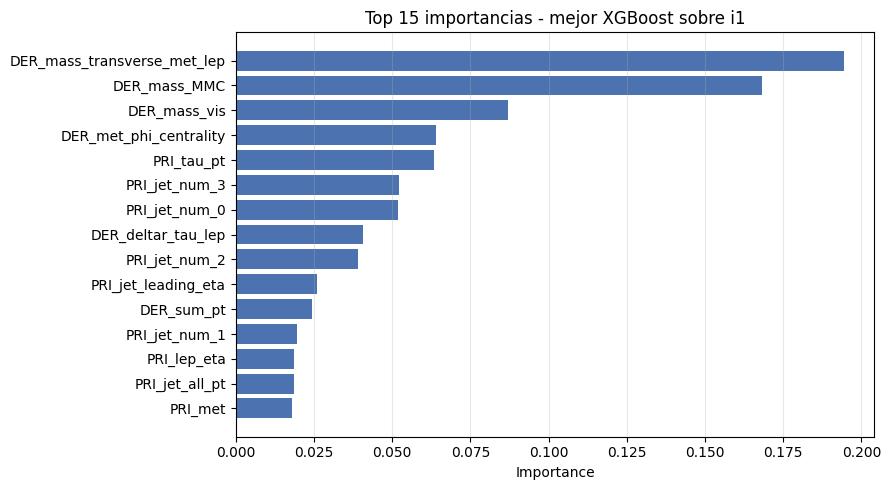

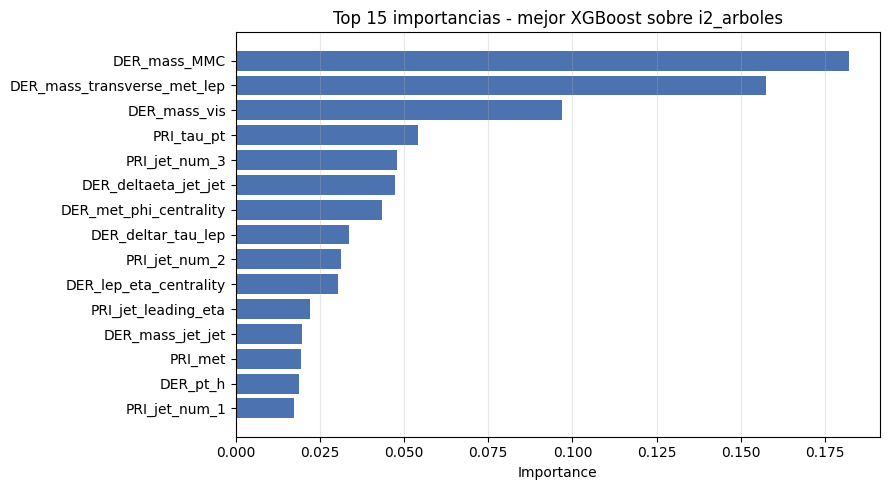

In [8]:
plot_top_feature_importances(
    best_xgboost_i1,
    X_i1_train.columns,
    "Top 15 importancias - mejor XGBoost sobre i1",
)

plot_top_feature_importances(
    best_xgboost_i2,
    X_i2_train.columns,
    "Top 15 importancias - mejor XGBoost sobre i2_arboles",
)

## Submission Higgs con `i2_arboles`

La generación sigue lo documentado en `docs/formato_submission_higgs.md`: el umbral se calibra sobre validación maximizando AMS ponderado con `train_weight.csv`, luego se arma el CSV final con `EventId`, `RankOrder` y `Class`.

In [9]:
i2_valid_scores = predict_scores(best_xgboost_i2, X_i2_valid)
i2_submission_threshold = find_best_ams_threshold(y_valid, i2_valid_scores, weight_valid)

i2_submission_threshold_df = pd.DataFrame(
    [
        {
            "model": "xgboost_i2_arboles",
            **i2_submission_threshold,
        }
    ]
)

print("Selección de umbral para submission sobre validación:")
display(i2_submission_threshold_df.round(6))

Selección de umbral para submission sobre validación:


,model,threshold,ams,signal_weight,background_weight,predicted_signal_count,predicted_background_count,precision,recall,f1,candidate_threshold_count
0,xgboost_i2_arboles,0.873858,1.086841,23.677405,456.782007,3965,21035,0.922825,0.427104,0.583945,24987


In [10]:
i2_test_scores = predict_scores(best_xgboost_i2, X_i2_test)
i2_submission_df = build_higgs_submission(
    event_ids=test_event_id,
    scores=i2_test_scores,
    threshold=i2_submission_threshold["threshold"],
)
i2_submission_validation = validate_higgs_submission(i2_submission_df)
i2_submission_path = save_higgs_submission(
    i2_submission_df,
    prefix="higgs_submission_i2_arboles_xgboost_best",
)

i2_submission_summary_df = pd.DataFrame(
    [
        {
            "threshold": i2_submission_threshold["threshold"],
            "validation_ams": i2_submission_threshold["ams"],
            "validation_signal_weight": i2_submission_threshold["signal_weight"],
            "validation_background_weight": i2_submission_threshold["background_weight"],
            "validation_predicted_signal_count": i2_submission_threshold["predicted_signal_count"],
            "rows": i2_submission_validation["rows"],
            "rank_min": i2_submission_validation["rank_min"],
            "rank_max": i2_submission_validation["rank_max"],
            "test_signal_count": i2_submission_validation["signal_count"],
            "test_background_count": i2_submission_validation["background_count"],
        }
    ]
)

print(f"Submission guardada en: {i2_submission_path}")
display(i2_submission_summary_df.round(6))
print("Primeras filas del archivo generado:")
display(i2_submission_df.head())

Submission guardada en: /home/santig14/fing/taa/1_TallerAA/results/higgs_submission_i2_arboles_xgboost_best_20260429_172019.csv


,threshold,validation_ams,validation_signal_weight,validation_background_weight,validation_predicted_signal_count,rows,rank_min,rank_max,test_signal_count,test_background_count
0,0.873858,1.086841,23.677405,456.782007,3965,550000,1,550000,85081,464919


Primeras filas del archivo generado:


,EventId,RankOrder,Class
0,350000,13314,b
1,350001,222049,b
2,350002,378414,b
3,350003,489186,s
4,350004,42927,b


In [ ]:
kaggle_credentials_path = project_root / "keys" / "kaggle.json"
kaggle_submit_message = "XGBoost sobre i2_arboles con umbral AMS calibrado en validacion"
kaggle_submit_command = build_kaggle_submit_command(i2_submission_path, kaggle_submit_message)

if not kaggle_credentials_path.exists():
    raise FileNotFoundError(f"No se encontró kaggle.json en: {kaggle_credentials_path}")

print(f"Credenciales locales detectadas en: {kaggle_credentials_path}")
print("Ejecutando submission a Kaggle:")
print(kaggle_submit_command)

# kaggle_submit_result = subprocess.run(
#     kaggle_submit_command,
#     shell=True,
#     check=False,
#     capture_output=True,
#     text=True,
# )

# if kaggle_submit_result.stdout:
#     print("stdout de Kaggle:")
#     print(kaggle_submit_result.stdout)
# if kaggle_submit_result.stderr:
#     print("stderr de Kaggle:")
#     print(kaggle_submit_result.stderr)

# if kaggle_submit_result.returncode != 0:
#     raise RuntimeError(
#         f"La submission a Kaggle falló con código {kaggle_submit_result.returncode}."
#     )

Credenciales locales detectadas en: /home/santig14/fing/taa/1_TallerAA/keys/kaggle.json
Comando sugerido para enviar la submission desde una terminal con acceso a internet:
KAGGLE_CONFIG_DIR=/home/santig14/fing/taa/1_TallerAA/keys kaggle competitions submit -c higgs-boson -f /home/santig14/fing/taa/1_TallerAA/results/higgs_submission_i2_arboles_xgboost_best_20260429_172019.csv -m 'XGBoost sobre i2_arboles con umbral AMS calibrado en validacion'


## Cierre

Este cuaderno no busca volver a optimizar hiperparámetros, sino aislar el efecto del preprocesamiento. La lectura correcta del resultado es:

- si `i2_arboles` mejora AUC/F1 frente a `i1`, entonces vale la pena seguir explorando árboles con esa representación;
- si `i1` sigue arriba, el pipeline con imputación y descarte sigue siendo la mejor base para esta familia de modelos;
- si la diferencia es mínima, la decisión puede apoyarse también en simplicidad del pipeline y costo computacional.

In [12]:
best_row = comparison_ranked_df.iloc[0]

print(
    f"Mejor variante por AUC en este notebook: {best_row['dataset']} "
    f"(AUC={best_row['auc']:.4f}, F1={best_row['f1']:.4f})."
)

if best_row["dataset"] == "i1":
    print(
        f"i2_arboles quedó por debajo de i1 en AUC por {abs(float(comparison_df.loc[comparison_df['dataset'] == 'i2_arboles', 'delta_auc_vs_i1'].iloc[0])):.4f}."
    )
else:
    print(
        f"i2_arboles superó a i1 en AUC por {float(comparison_df.loc[comparison_df['dataset'] == 'i2_arboles', 'delta_auc_vs_i1'].iloc[0]):.4f}."
    )

print(
    f"Submission i2_arboles lista en: {i2_submission_path.name} "
    f"con threshold={i2_submission_threshold['threshold']:.6f} y AMS(valid)={i2_submission_threshold['ams']:.6f}."
)

Mejor variante por AUC en este notebook: i2_arboles (AUC=0.9090, F1=0.7688).
i2_arboles superó a i1 en AUC por 0.0033.
Submission i2_arboles lista en: higgs_submission_i2_arboles_xgboost_best_20260429_172019.csv con threshold=0.873858 y AMS(valid)=1.086841.
